# Digital Image Processing — Lab Task 02
## Digital Images, Pixels, Color, and Basic Transformations

**Name:** Shahzad Ahmed Awan  
**Roll No.:** 2024-SE-15

## Step 1: Create the Project and Virtual Environment

```
mkdir dip-lab-02
cd dip-lab-02
python -m venv .venv
.venv\Scripts\activate.bat          (PowerShell: .venv\Scripts\Activate.ps1)
pip install numpy opencv-python matplotlib
echo .venv/ > .gitignore
```

In [33]:
import os
import sys
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


def banner(title):
    """Print a clear section header so outputs are easy to tell apart."""
    print("=" * 62)
    print(title)
    print("=" * 62)


banner("STEP 1 — ENVIRONMENT CHECK")

print("Python")
print(f"  Executable         : {sys.executable}")
print(f"  Version            : {sys.version.split()[0]}")
print(f"  Inside virtual env : {sys.prefix != sys.base_prefix}")
print(f"  Working folder     : {os.getcwd()}")

print("\nLibrary versions")
print(f"  NumPy              : {np.__version__}")
print(f"  OpenCV             : {cv.__version__}")
print(f"  Matplotlib         : {matplotlib.__version__}")

# .gitignore must exclude the virtual environment
entries = open(".gitignore").read().split() if os.path.exists(".gitignore") else []
if ".venv/" not in entries:
    with open(".gitignore", "a") as f:
        f.write(".venv/\n")
    entries.append(".venv/")

print("\n.gitignore")
print(f"  Entries            : {entries}")
print(f"  .venv/ ignored     : {'.venv/' in entries}")

STEP 1 — ENVIRONMENT CHECK
Python
  Executable         : c:\Users\ShahzadAhmedAwan\Desktop\dip-lab-02\.venv\Scripts\python.exe
  Version            : 3.14.8
  Inside virtual env : True
  Working folder     : c:\Users\ShahzadAhmedAwan\Desktop\dip-lab-02

Library versions
  NumPy              : 2.5.4
  OpenCV             : 5.0.0
  Matplotlib         : 3.11.2

.gitignore
  Entries            : ['.venv/']
  .venv/ ignored     : True


## Step 2: Load the Image

In [34]:
IMAGE_PATH = "my_image.jpeg"      # <- must match your image's file name exactly

image = cv.imread(IMAGE_PATH)
if image is None:
    raise FileNotFoundError(f"Image not found or unreadable: {IMAGE_PATH}")
if min(image.shape[:2]) < 300:
    raise ValueError(f"Image must be at least 300 x 300 pixels, got {image.shape[1]} x {image.shape[0]}")

banner("STEP 2 — IMAGE LOADED")
print(f"  File       : {IMAGE_PATH}")
print(f"  Shape      : {image.shape}   (height, width, channels)")
print(f"  Data type  : {image.dtype}")

STEP 2 — IMAGE LOADED
  File       : my_image.jpeg
  Shape      : (1792, 2400, 3)   (height, width, channels)
  Data type  : uint8


## Step 3: Inspect the Image

In [35]:
height, width, channels = image.shape
cy, cx = height // 2, width // 2          # center as [row, column] = [y, x]

top_left = image[0, 0]
center   = image[cy, cx]

banner("STEP 3 — IMAGE INSPECTION")

print("Dimensions")
print(f"  Height          : {height} px")
print(f"  Width           : {width} px")
print(f"  Channels        : {channels}  (Blue, Green, Red)")
print(f"  Total pixels    : {height * width:,}")

print("\nPixel values   image[row, column]  ->  (B, G, R)")
print(f"  Top-left [0, 0]       : B = {top_left[0]:>3}   G = {top_left[1]:>3}   R = {top_left[2]:>3}")
print(f"  Center [{cy}, {cx}]     : B = {center[0]:>3}   G = {center[1]:>3}   R = {center[2]:>3}")

print("\nValue range (0 = darkest, 255 = brightest)")
print(f"  {'Scope':<16}{'Minimum':>8}{'Maximum':>9}")
print(f"  {'-' * 33}")
print(f"  {'Global':<16}{image.min():>8}{image.max():>9}")
for i, name in enumerate(["Blue channel", "Green channel", "Red channel"]):
    print(f"  {name:<16}{image[:, :, i].min():>8}{image[:, :, i].max():>9}")

STEP 3 — IMAGE INSPECTION
Dimensions
  Height          : 1792 px
  Width           : 2400 px
  Channels        : 3  (Blue, Green, Red)
  Total pixels    : 4,300,800

Pixel values   image[row, column]  ->  (B, G, R)
  Top-left [0, 0]       : B =   0   G =   4   R =   0
  Center [896, 1200]     : B =   0   G =   0   R = 112

Value range (0 = darkest, 255 = brightest)
  Scope            Minimum  Maximum
  ---------------------------------
  Global                 0      255
  Blue channel           0      255
  Green channel          0      255
  Red channel            0      255


## Step 4: Convert Colors and Separate Channels

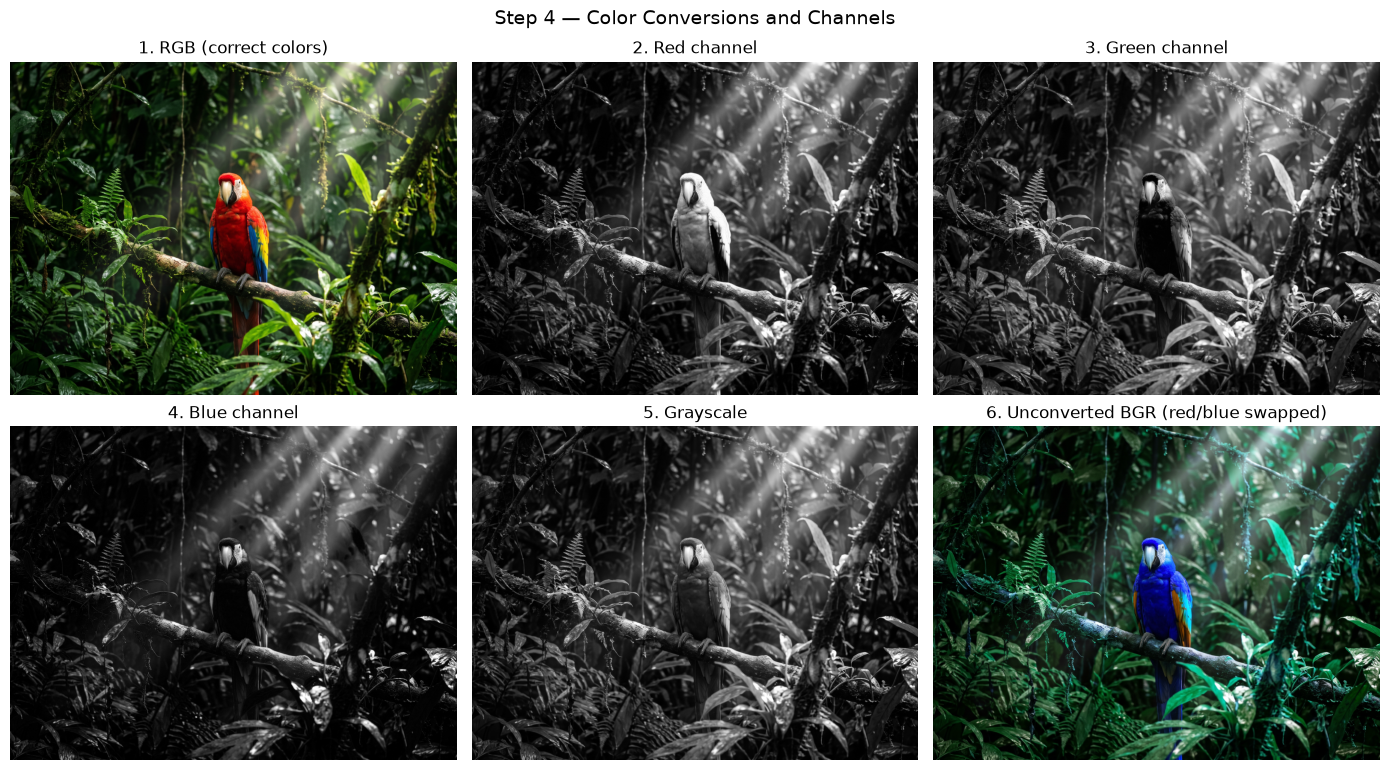

STEP 4 — CENTER PIXEL COLOR
  Position   : [896, 1200]
  RGB        : (112, 0, 0)
  HEX        : #700000


In [36]:
rgb  = cv.cvtColor(image, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
red, green, blue = cv.split(rgb)

views = [
    (rgb,   "1. RGB (correct colors)", None),
    (red,   "2. Red channel",          "gray"),
    (green, "3. Green channel",        "gray"),
    (blue,  "4. Blue channel",         "gray"),
    (gray,  "5. Grayscale",            "gray"),
    (image, "6. Unconverted BGR (red/blue swapped)", None),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (img, title, cmap) in zip(axes.ravel(), views):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Step 4 — Color Conversions and Channels", fontsize=14)
plt.tight_layout()
plt.show()

r, g, b = (int(v) for v in rgb[cy, cx])

banner("STEP 4 — CENTER PIXEL COLOR")
print(f"  Position   : [{cy}, {cx}]")
print(f"  RGB        : ({r}, {g}, {b})")
print(f"  HEX        : #{r:02X}{g:02X}{b:02X}")

### Explanation: BGR vs RGB

**RGB**  
Each pixel is stored as `[Red, Green, Blue]`. This is the order Matplotlib and most other libraries (such as PIL) expect.

**BGR**  
Each pixel is stored as `[Blue, Green, Red]`. This is the order OpenCV uses when `cv.imread()` loads an image, kept for historical compatibility with early camera and image formats such as Windows BMP.

**Difference**

| | RGB | BGR |
|---|---|---|
| Channel order | Red, Green, Blue | Blue, Green, Red |
| First value `[0]` | Red | Blue |
| Pure red pixel | `[255, 0, 0]` | `[0, 0, 255]` |
| Used by | Matplotlib, PIL | OpenCV |

Both hold the same three numbers per pixel; only their order is reversed.

**Why the order matters**  
If a BGR array is shown by Matplotlib without conversion, red and blue are swapped. For example, a blue pixel `[200, 50, 30]` (B=200, G=50, R=30) is drawn as R=200, G=50, B=30, which is orange-red. Greens and grays barely change because green stays in the middle and grays have equal values.

**In this lab**  
Panel 6 shows the unconverted BGR image with red and blue swapped, while panel 1 is correct after `cv.COLOR_BGR2RGB`. In Step 5 the image is converted back with `cv.COLOR_RGB2BGR` before saving, because `cv.imwrite()` expects BGR.

## Step 5: Crop, Resize, and Save

STEP 5 — CROP AND RESIZE
Crop region
  Rows (y)       : 846 to 946
  Columns (x)    : 1150 to 1250
  Crop shape     : (100, 100, 3)

Resized
  Resized shape  : (200, 200, 3)


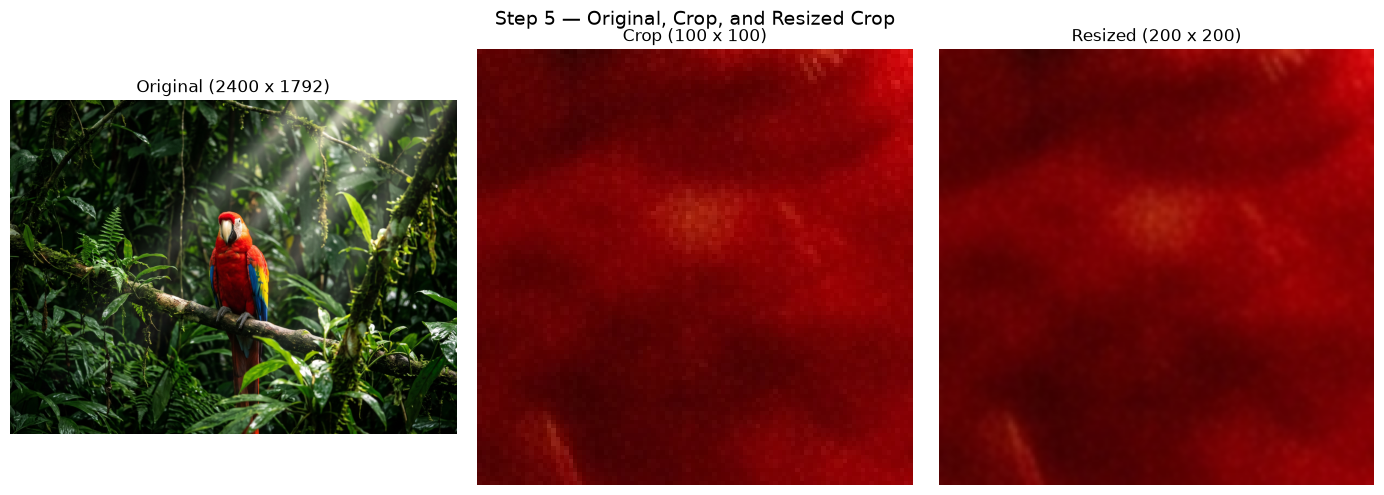


Saving
  File                  : resized_crop.png
  cv.imwrite() success  : True
  Re-read shape         : (200, 200, 3)


In [37]:
y_start, y_end = cy - 50, cy + 50
x_start, x_end = cx - 50, cx + 50

crop = rgb[y_start:y_end, x_start:x_end]
assert crop.shape[:2] == (100, 100), f"Crop must be 100 x 100, got {crop.shape[:2]}"

resized = cv.resize(crop, (200, 200))      # (width, height)

banner("STEP 5 — CROP AND RESIZE")
print("Crop region")
print(f"  Rows (y)       : {y_start} to {y_end}")
print(f"  Columns (x)    : {x_start} to {x_end}")
print(f"  Crop shape     : {crop.shape}")
print("\nResized")
print(f"  Resized shape  : {resized.shape}")

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
panels = [
    (rgb,     f"Original ({width} x {height})"),
    (crop,    "Crop (100 x 100)"),
    (resized, "Resized (200 x 200)"),
]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Step 5 — Original, Crop, and Resized Crop", fontsize=14)
plt.tight_layout()
plt.show()

saved = cv.imwrite("resized_crop.png", cv.cvtColor(resized, cv.COLOR_RGB2BGR))
check = cv.imread("resized_crop.png")

print("\nSaving")
print(f"  File                  : resized_crop.png")
print(f"  cv.imwrite() success  : {saved}")
print(f"  Re-read shape         : {check.shape if check is not None else 'FAILED'}")

## Step 6: Create a Histogram

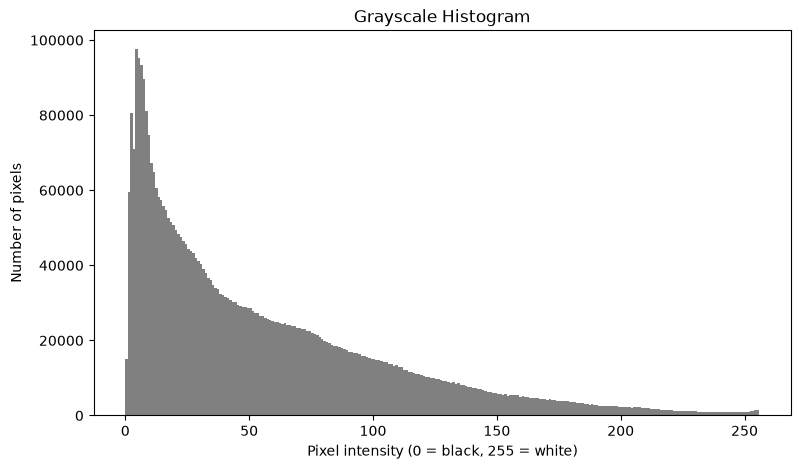

STEP 6 — HISTOGRAM STATISTICS
  Mean intensity        : 55.4 / 255
  Dark pixels   (<85)   :  76.0 %
  Mid-tones  (85-170)   :  20.1 %
  Bright pixels (>170)  :   3.9 %
  Plot saved as         : grayscale_histogram.png


### Interpretation

The grayscale histogram has a mean intensity of **55.4 out of 255**, with **76.0%** of pixels in the dark range and **3.9%** in the bright range. The image is therefore **mainly dark**. Most pixels sit at the low-intensity end, and only a thin tail reaches the bright end.

In [38]:
plt.figure(figsize=(9, 5))
plt.hist(gray.flatten(), bins=256, range=(0, 256), color="gray")
plt.title("Grayscale Histogram")
plt.xlabel("Pixel intensity (0 = black, 255 = white)")
plt.ylabel("Number of pixels")
plt.savefig("grayscale_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

mean   = gray.mean()
dark   = (gray < 85).mean() * 100
mid    = ((gray >= 85) & (gray <= 170)).mean() * 100
bright = (gray > 170).mean() * 100

banner("STEP 6 — HISTOGRAM STATISTICS")
print(f"  Mean intensity        : {mean:.1f} / 255")
print(f"  Dark pixels   (<85)   : {dark:5.1f} %")
print(f"  Mid-tones  (85-170)   : {mid:5.1f} %")
print(f"  Bright pixels (>170)  : {bright:5.1f} %")
print(f"  Plot saved as         : grayscale_histogram.png")

# Interpretation generated from the measured values above
if mean < 85:
    verdict = "mainly dark"
    detail = "Most pixels sit at the low-intensity end, and only a thin tail reaches the bright end."
elif mean > 170:
    verdict = "mainly bright"
    detail = "Most pixels sit at the high-intensity end, and only a thin tail reaches the dark end."
else:
    verdict = "balanced"
    detail = "Pixels are spread across the dark, mid, and bright ranges without one end dominating."

display(Markdown(
    f"### Interpretation\n\n"
    f"The grayscale histogram has a mean intensity of **{mean:.1f} out of 255**, with "
    f"**{dark:.1f}%** of pixels in the dark range and **{bright:.1f}%** in the bright range. "
    f"The image is therefore **{verdict}**. {detail}"
))

### Explanation: What a histogram shows and does not show

**What it shows.** A histogram counts how many pixels fall into each of the 256 intensity values. From that count alone you can read:

- **Overall brightness:** mass on the left means a dark image, on the right a bright one, in the middle a balanced one.
- **Contrast:** a narrow cluster means flat, low contrast; a wide spread means strong contrast.
- **Clipping:** tall spikes at 0 or 255 mean detail has been lost to pure black or pure white.
- **Dominant tones:** separate peaks usually indicate distinct regions, such as a dark background and a bright subject.

**What it does not show.**

- **Position:** the histogram only counts values. If every pixel were shuffled randomly, the picture would be destroyed but the histogram would stay identical.
- **Content:** two completely unrelated photographs can have the same histogram, so it cannot tell what the image contains.
- **Color:** a grayscale histogram merges the three channels into one brightness value, so a red area and a green area of equal brightness look the same.
- **Structure:** edges, texture, and sharpness are invisible to it, and blurring an image barely changes it.
- **Cause:** it shows that an image is dark, but not whether the scene itself was dark or the photo was underexposed.

## Step 7: Demonstrate Bit Depth

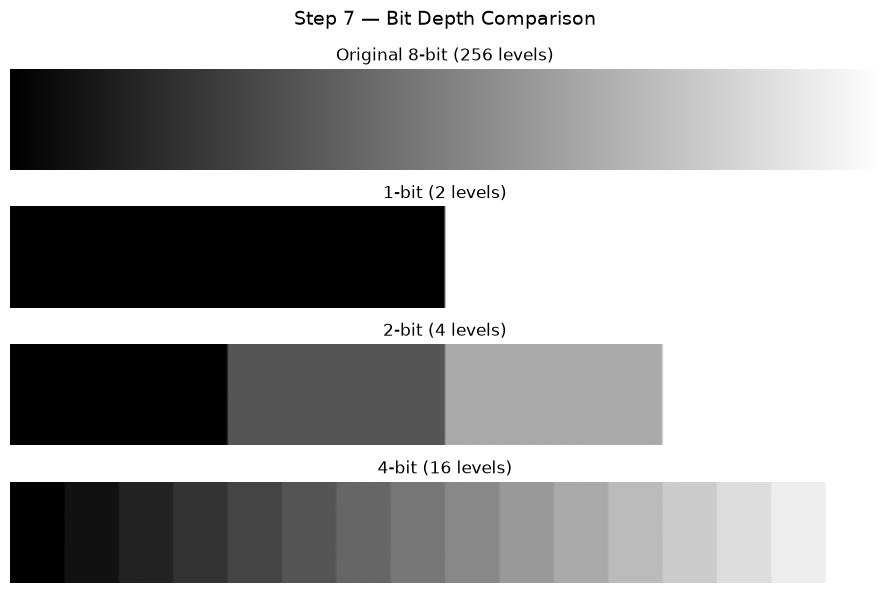

STEP 7 — UNIQUE VALUE COUNTS
  Image                         Unique  Expected   Result
  -------------------------------------------------------
  Original 8-bit (256 levels)      256       256       OK
  1-bit (2 levels)                   2         2       OK
  2-bit (4 levels)                   4         4       OK
  4-bit (16 levels)                 16        16       OK


In [39]:
gradient = np.tile(np.arange(256, dtype=np.uint8), (100, 1))      # 8-bit horizontal ramp, 0 to 255


def quantize(img, bits):
    levels = 2 ** bits
    return ((img // (256 // levels)) * (255 // (levels - 1))).astype(np.uint8)


panels = [
    (gradient,              "Original 8-bit (256 levels)", 8),
    (quantize(gradient, 1), "1-bit (2 levels)",            1),
    (quantize(gradient, 2), "2-bit (4 levels)",            2),
    (quantize(gradient, 4), "4-bit (16 levels)",           4),
]

fig, axes = plt.subplots(4, 1, figsize=(9, 6))
for ax, (img, title, bits) in zip(axes, panels):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Step 7 — Bit Depth Comparison", fontsize=14)
plt.tight_layout()
plt.show()

banner("STEP 7 — UNIQUE VALUE COUNTS")
print(f"  {'Image':<28}{'Unique':>8}{'Expected':>10}{'Result':>9}")
print(f"  {'-' * 55}")
for img, title, bits in panels:
    unique, expected = len(np.unique(img)), 2 ** bits
    print(f"  {title:<28}{unique:>8}{expected:>10}{'OK' if unique == expected else 'FAIL':>9}")

### Explanation: Resolution vs bit depth

**Resolution** is the number of pixels, width × height. It controls **spatial detail**: how finely the scene is sampled across the image. Lowering it leaves fewer samples, so edges turn into staircases, small details disappear, and the image looks **blocky**. In this lab, the 100 × 100 crop and the 200 × 200 resized version differ in resolution.

**Bit depth** is the number of bits used for each pixel value, which sets the number of distinct intensities: 2ⁿ. That gives 2 levels for 1-bit, 4 for 2-bit, 16 for 4-bit, and 256 for 8-bit. It controls **tonal precision**: how smoothly brightness can change. Lowering it causes **banding**, where a smooth gradient turns into visible steps. In Step 7 the gradient keeps all 256 columns (resolution unchanged), yet it shows only 2, 4, or 16 shades as the bit depth drops.

**They are independent.** An image can have high resolution and low bit depth (many pixels, few shades) or the reverse. Both affect file size, which is roughly `width × height × bits per pixel ÷ 8` bytes. A 640 × 480 grayscale image at 8 bits needs about 307,200 bytes. Reducing it to 2 bits cuts that to 76,800 bytes, and halving the resolution to 320 × 240 at 8 bits also gives 76,800 bytes, yet the first result looks banded while the second looks blocky.

**In short:** resolution answers "how many samples are there?", and bit depth answers "how precise is each sample?".

## Step 8: Complete the Project

In [40]:
banner("STEP 8 — FINAL CHECK")
print(f"  {'File':<28}{'Status':<10}{'Size':>10}")
print(f"  {'-' * 48}")
for name in [IMAGE_PATH, "resized_crop.png", "grayscale_histogram.png", ".gitignore"]:
    if os.path.exists(name):
        print(f"  {name:<28}{'found':<10}{os.path.getsize(name) / 1024:>8.1f} KB")
    else:
        print(f"  {name:<28}{'MISSING':<10}")
print("\nAll cells completed successfully.")

STEP 8 — FINAL CHECK
  File                        Status          Size
  ------------------------------------------------
  my_image.jpeg               found       3381.0 KB
  resized_crop.png            found         37.6 KB
  grayscale_histogram.png     found         27.3 KB
  .gitignore                  found          0.0 KB

All cells completed successfully.
